# 02. What actually differs between the VR twin and the physical workstation?

Both datasets come from the same Perception Neuron suit with an identical skeleton, so the domain gap is **not** a sensor gap (the legacy paper's Kinect-noise story was wrong). This notebook measures the real gap with clip-level kinematic descriptors (`picda/gap_analysis.py`):

* execution time, heading (world yaw) and locomotion of the hips;
* wrist speed, hand height and reach, trunk flexion, elbow range;
* smoothness (log dimensionless jerk) and high-frequency content of the wrist (a jitter proxy).

It then asks how separable the domains are (domain classifier, subject-grouped CV) and gives a non-deep transfer baseline. These results drive the method design of Step 2.

**What to send back:** all printed tables and the figures.

In [8]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import GroupKFold

from picda import config as C
from picda.data import load_index, load_raw
from picda.gap_analysis import descriptor_table, domain_shift_tests

GAP_DIR = C.OUTPUT_DIR / 'gap'
GAP_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200)

In [9]:
index = load_index()
raw = load_raw(index, 'body19')
desc = descriptor_table(index, raw)
desc.to_csv(GAP_DIR / 'descriptors.csv', index=False)
FEATS = [c for c in desc.columns if c not in ('clip_id', 'domain', 'subject', 'session', 'label', 'class_folder')]
print(len(desc), 'clips,', len(FEATS), 'descriptors')
print(desc.groupby('domain')[FEATS].median().T.round(3).to_string())

9499 clips, 17 descriptors
domain                   dt     real
duration_s            2.467    1.900
facing_yaw_deg      -59.507  109.549
root_displacement_m   0.036    0.035
root_path_m           0.104    0.075
rwrist_mean_speed     0.251    0.190
rwrist_peak_speed     0.627    0.459
lwrist_mean_speed     0.166    0.153
lwrist_peak_speed     0.379    0.381
right_hand_share      0.616    0.551
hand_height_torso     0.356    0.436
hand_reach_torso      0.954    0.864
trunk_flexion_deg     5.372    6.562
relbow_range_deg     23.887   18.407
lelbow_range_deg      8.286   15.020
rwrist_ldlj         -10.108  -10.279
rwrist_hf_ratio       0.014    0.063
head_height_torso     1.162    1.160


## 1. Global and per-class shifts

Mann-Whitney U per descriptor, Benjamini-Hochberg corrected. Cliff's delta is in [-1, 1]; positive means larger in the DT. |delta| > 0.33 is usually read as a medium effect, > 0.47 large.

            feature  dt_median  real_median  cliffs_delta   q_bh
     facing_yaw_deg   -59.5068     109.5488       -0.9963 0.0000
    rwrist_hf_ratio     0.0140       0.0628       -0.6202 0.0000
  hand_height_torso     0.3558       0.4363       -0.2824 0.0000
   lelbow_range_deg     8.2856      15.0200       -0.2068 0.0000
   hand_reach_torso     0.9544       0.8640        0.1948 0.0000
        root_path_m     0.1037       0.0749        0.1680 0.0000
  trunk_flexion_deg     5.3715       6.5622       -0.1642 0.0000
         duration_s     2.4667       1.9000        0.1504 0.0000
        rwrist_ldlj   -10.1082     -10.2787        0.1397 0.0000
  rwrist_peak_speed     0.6268       0.4590        0.0987 0.0000
  rwrist_mean_speed     0.2514       0.1902        0.0911 0.0000
   right_hand_share     0.6161       0.5511        0.0718 0.0000
   relbow_range_deg    23.8872      18.4069        0.0634 0.0000
  head_height_torso     1.1616       1.1601        0.0631 0.0000
root_displacement_m     0

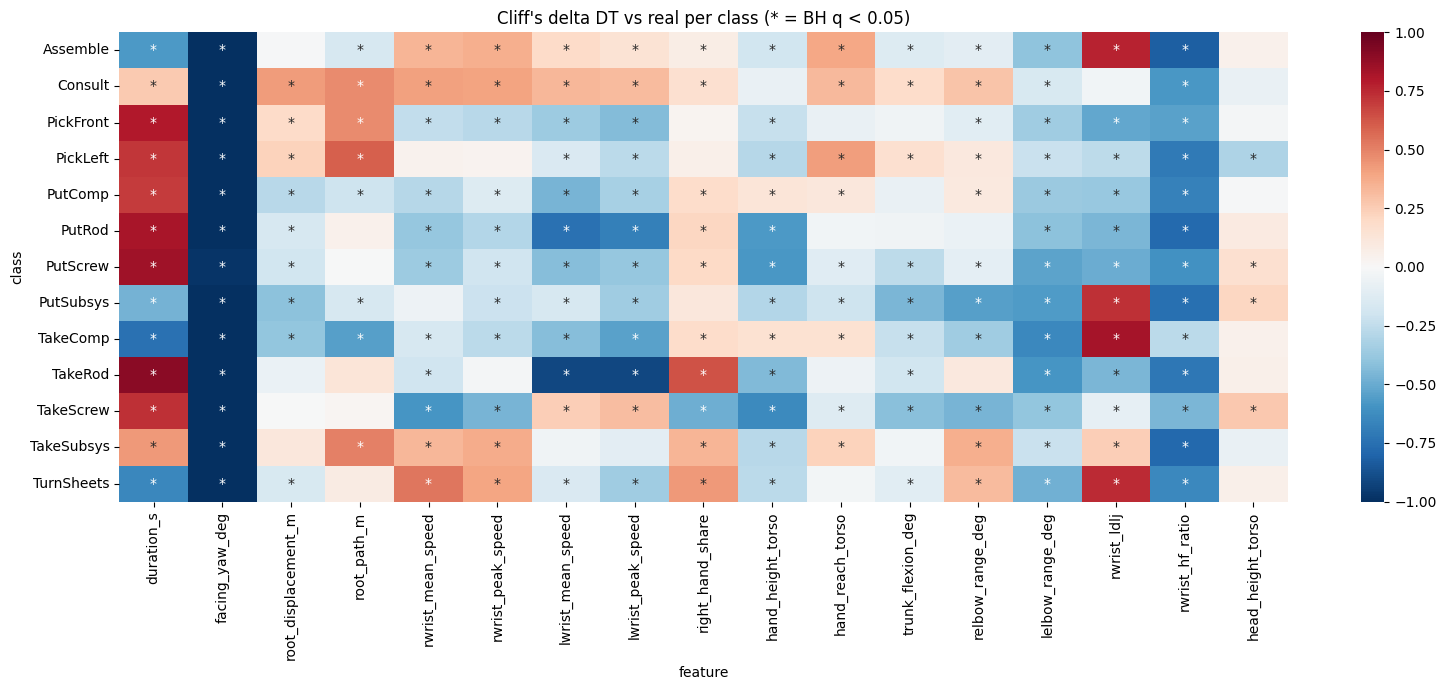

In [10]:
glob = domain_shift_tests(desc, FEATS, by_class=False)
glob = glob.reindex(glob.cliffs_delta.abs().sort_values(ascending=False).index)
print(glob[['feature', 'dt_median', 'real_median', 'cliffs_delta', 'q_bh']].round(4).to_string(index=False))
glob.to_csv(GAP_DIR / 'shift_global.csv', index=False)

per_class = domain_shift_tests(desc, FEATS, by_class=True)
per_class.to_csv(GAP_DIR / 'shift_per_class.csv', index=False)
piv = per_class.pivot(index='class', columns='feature', values='cliffs_delta').reindex(index=C.CLASS_NAMES, columns=FEATS)
sig = per_class.pivot(index='class', columns='feature', values='q_bh').reindex(index=C.CLASS_NAMES, columns=FEATS) < 0.05
plt.figure(figsize=(16, 7))
sns.heatmap(piv, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=np.where(sig.values, '*', ''), fmt='',
            yticklabels=C.SHORT_NAMES)
plt.title("Cliff's delta DT vs real per class (* = BH q < 0.05)")
plt.tight_layout()
plt.savefig(GAP_DIR / 'shift_heatmap.png', dpi=200)
plt.show()

## 2. Heading: why orientation canonicalisation is needed

If the two workstations face different world directions, a network fed raw coordinates can tell the domains apart from absolute heading alone. `picda.skeleton.canonicalize` rotates each clip so its first-frame hip line points along +X; notebook 03 can ablate this with `canon_yaw='none'`.

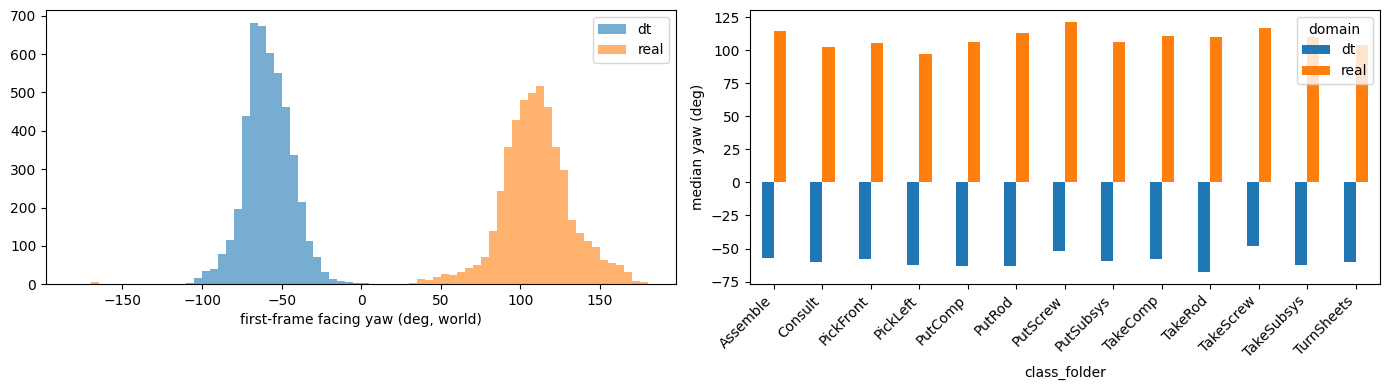

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), subplot_kw={})
for d, col in [('dt', 'tab:blue'), ('real', 'tab:orange')]:
    axes[0].hist(desc.loc[desc.domain == d, 'facing_yaw_deg'], bins=72, range=(-180, 180), alpha=0.6, label=d, color=col)
axes[0].set_xlabel('first-frame facing yaw (deg, world)')
axes[0].legend()
sub = desc.groupby(['domain', 'class_folder']).facing_yaw_deg.median().unstack(0).loc[C.CLASS_NAMES]
sub.plot.bar(ax=axes[1])
axes[1].set_xticklabels(C.SHORT_NAMES, rotation=45, ha='right')
axes[1].set_ylabel('median yaw (deg)')
plt.tight_layout()
plt.savefig(GAP_DIR / 'facing_yaw.png', dpi=200)
plt.show()

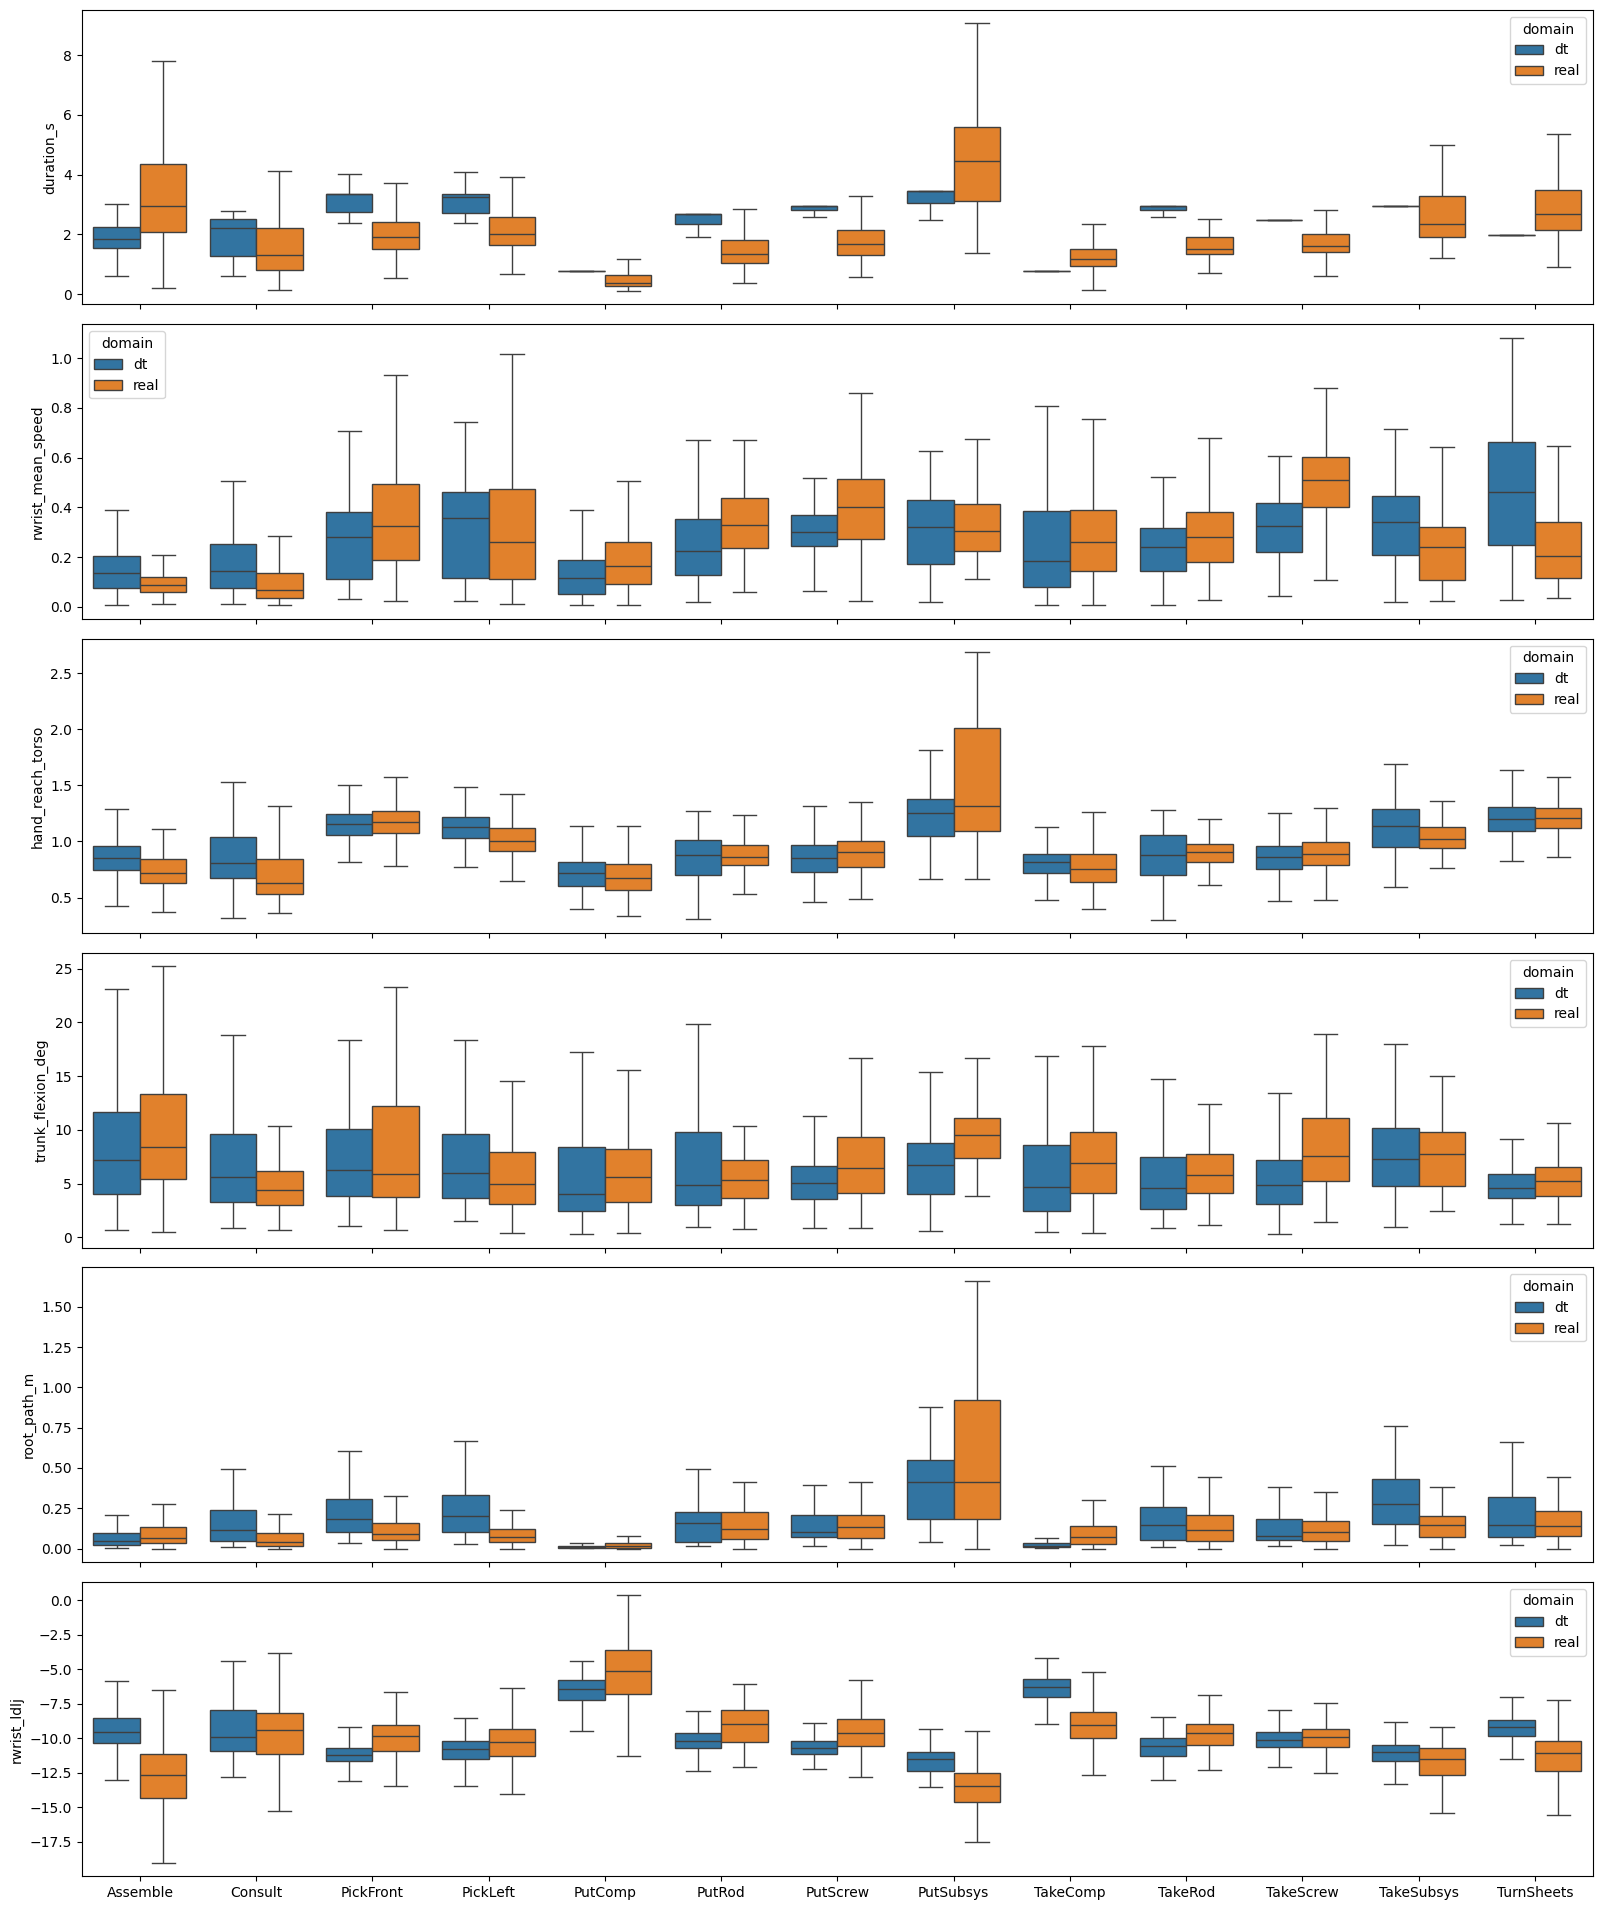

In [12]:
KEY = ['duration_s', 'rwrist_mean_speed', 'hand_reach_torso', 'trunk_flexion_deg', 'root_path_m', 'rwrist_ldlj']
fig, axes = plt.subplots(len(KEY), 1, figsize=(16, 3.2 * len(KEY)))
for ax, f in zip(axes, KEY):
    sns.boxplot(data=desc, x='class_folder', y=f, hue='domain', order=C.CLASS_NAMES, showfliers=False, ax=ax)
    ax.set_xticks(range(len(C.CLASS_NAMES)))
    ax.set_xticklabels(C.SHORT_NAMES if ax is axes[-1] else [])
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig(GAP_DIR / 'key_descriptors_per_class.png', dpi=200)
plt.show()

## 3. How separable are the domains?

A gradient-boosting domain classifier on the descriptors, 5-fold CV grouped by subject (a subject never appears in both train and test). AUC near 0.5 means the domains look alike at this level; near 1 means easily separable. Run with and without the heading descriptor.

In [13]:
y_dom = (desc.domain == 'dt').astype(int).values
groups = (desc.domain + '_' + desc.subject).values

def domain_auc(cols):
    X = desc[cols].values
    scores = np.zeros(len(desc))
    for tr, te in GroupKFold(n_splits=5).split(X, y_dom, groups):
        clf = HistGradientBoostingClassifier(max_iter=300, random_state=0).fit(X[tr], y_dom[tr])
        scores[te] = clf.predict_proba(X[te])[:, 1]
    return roc_auc_score(y_dom, scores)

no_yaw = [f for f in FEATS if f != 'facing_yaw_deg']
print(f'Domain AUC, all descriptors      : {domain_auc(FEATS):.3f}')
print(f'Domain AUC, without facing yaw   : {domain_auc(no_yaw):.3f}')
print(f'Domain AUC, duration only        : {domain_auc(["duration_s"]):.3f}')

X = desc[no_yaw].values
tr, te = next(GroupKFold(n_splits=5).split(X, y_dom, groups))
clf = HistGradientBoostingClassifier(max_iter=300, random_state=0).fit(X[tr], y_dom[tr])
imp = permutation_importance(clf, X[te], y_dom[te], scoring='roc_auc', n_repeats=10, random_state=0)
print(pd.Series(imp.importances_mean, index=no_yaw).sort_values(ascending=False).round(4).to_string())

Domain AUC, all descriptors      : 1.000
Domain AUC, without facing yaw   : 0.974
Domain AUC, duration only        : 0.874
duration_s             0.2147
rwrist_hf_ratio        0.0571
lelbow_range_deg       0.0515
root_path_m            0.0508
lwrist_peak_speed      0.0233
hand_height_torso      0.0173
hand_reach_torso       0.0112
rwrist_ldlj            0.0106
head_height_torso      0.0079
lwrist_mean_speed      0.0032
rwrist_mean_speed      0.0026
right_hand_share       0.0022
root_displacement_m    0.0012
relbow_range_deg       0.0012
rwrist_peak_speed     -0.0007
trunk_flexion_deg     -0.0042


## 4. Non-deep reference: action classification from descriptors

Same descriptors (without heading), gradient boosting. DT->real is a handcrafted zero-shot transfer; real->real uses 4 subject-grouped folds. Any deep method must clearly beat these.

In [14]:
dt, real = desc[desc.domain == 'dt'], desc[desc.domain == 'real']
clf = HistGradientBoostingClassifier(max_iter=300, random_state=0).fit(dt[no_yaw], dt.label)
p = clf.predict(real[no_yaw])
print(f'Descriptors DT -> real   : acc={np.mean(p == real.label):.4f} macroF1={f1_score(real.label, p, average="macro"):.4f}')

preds = np.zeros(len(real), dtype=int)
for tr, te in GroupKFold(n_splits=4).split(real, real.label, real.subject):
    m = HistGradientBoostingClassifier(max_iter=300, random_state=0).fit(real[no_yaw].iloc[tr], real.label.iloc[tr])
    preds[te] = m.predict(real[no_yaw].iloc[te])
print(f'Descriptors real -> real : acc={np.mean(preds == real.label.values):.4f} macroF1={f1_score(real.label, preds, average="macro"):.4f}')

Descriptors DT -> real   : acc=0.2896 macroF1=0.1822
Descriptors real -> real : acc=0.6708 macroF1=0.5258


## 5. Two follow-up checks

**(a) Segment boundaries.** 58% of InHARD-DT clips have one of only five durations (3.0, 0.8, 2.5, 2.0, 3.4 s), while InHARD durations are spread out. The DT generator seems to cut fixed windows around VR events, whereas InHARD was annotated by hand. If so, "VR actions are slower" is an annotation artefact, not behaviour. This cell shows the duration histograms and which classes the fixed windows belong to.

**(b) Where does the extra high-frequency power in InHARD come from?** Real wrists carry about 4x more power above 4 Hz. If the hips, head and feet (which barely move while standing at a workstation) show the same excess, it is sensor-level noise (for example magnetic interference on the IMU suit near the metal workstation). If only the hands do, it reflects physical manipulation and tool contact that VR lacks.

dt: 293 distinct durations, top-5 values cover 58.1% of clips
    {3.0: np.int64(767), 0.8: np.int64(743), 2.5: np.int64(415), 2.0: np.int64(410), 3.4: np.int64(394)}
real: 258 distinct durations, top-5 values cover 10.0% of clips
    {1.44: np.int64(101), 1.52: np.int64(98), 1.36: np.int64(95), 1.32: np.int64(94), 1.6: np.int64(92)}

DT clips on a fixed window, per class (share of that class):
class_folder
Put down subsystem        0.01
Put down measuring rod    0.01
Assemble system           0.02
Consult sheets            0.02
Picking left              0.47
Picking in front          0.57
Take measuring rod        0.67
Put down screwdriver      0.70
Take screwdriver          0.75
Turn sheets               0.86
Put down component        0.97
Take component            0.97
Take subsystem            0.99


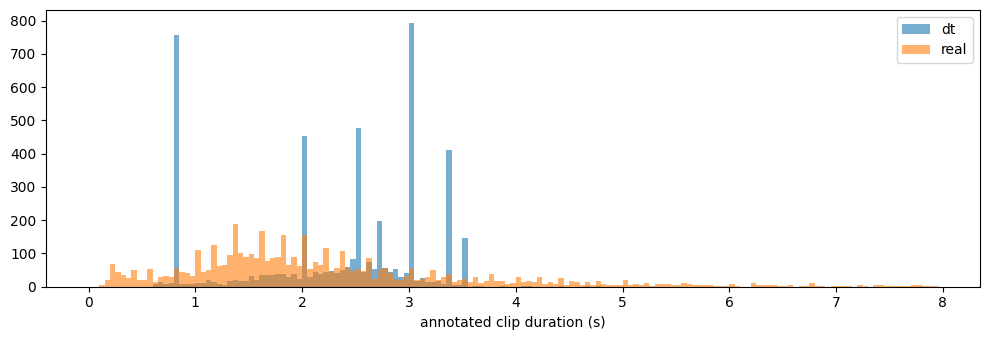


Median share of velocity power above 4 Hz, per joint:
domain            dt    real  real/dt
Hips          0.0411  0.0794   1.9324
Spine3        0.0214  0.0457   2.1406
Head          0.0304  0.0539   1.7704
RightFoot     0.1365  0.1875   1.3736
RightForeArm  0.0238  0.0619   2.5985
RightHand     0.0140  0.0628   4.4714
LeftHand      0.0195  0.0712   3.6443


In [15]:
from picda.gap_analysis import _hf_ratio
from picda.skeleton import joint_names

# (a) segment boundaries
dur = index.assign(dur=(index.end_s - index.start_s).round(2))
for d in ['dt', 'real']:
    x = dur[dur.domain == d]
    top = x.dur.value_counts().head(5)
    print(f'{d}: {x.dur.nunique()} distinct durations, top-5 values cover {100 * top.sum() / len(x):.1f}% of clips')
    print('   ', dict(top))
fixed = dur[(dur.domain == 'dt') & dur.dur.isin([3.0, 0.8, 2.5, 2.0, 3.4])]
print()
print('DT clips on a fixed window, per class (share of that class):')
print((fixed.class_folder.value_counts() / dur[dur.domain == 'dt'].class_folder.value_counts()).round(2).sort_values().to_string())
fig, ax = plt.subplots(figsize=(10, 3.5))
for d, col in [('dt', 'tab:blue'), ('real', 'tab:orange')]:
    ax.hist(dur.loc[dur.domain == d, 'dur'], bins=np.arange(0, 8, 0.05), alpha=0.6, label=d, color=col)
ax.set_xlabel('annotated clip duration (s)')
ax.legend()
plt.tight_layout()
plt.savefig(GAP_DIR / 'duration_histogram.png', dpi=200)
plt.show()

# (b) high-frequency share per joint
n19 = joint_names('body19')
JOINTS = ['Hips', 'Spine3', 'Head', 'RightFoot', 'RightForeArm', 'RightHand', 'LeftHand']
hf = pd.DataFrame([{**{'domain': d}, **{j: _hf_ratio(c[:, n19.index(j)] / 100.0) for j in JOINTS}}
                   for d, c in zip(index.domain, raw)])
print()
print('Median share of velocity power above 4 Hz, per joint:')
med = hf.groupby('domain')[JOINTS].median().T
med['real/dt'] = med['real'] / med['dt']
print(med.round(4).to_string())

In [16]:
# (c) The share above is inflated wherever voluntary motion is small (real hips travel less than DT hips),
# so compare the ABSOLUTE power above 4 Hz as well. Similar real/dt ratios on every joint => broadband
# sensor-level noise; hands far above trunk => manipulation content.
import importlib, picda.gap_analysis as ga
importlib.reload(ga)
hfp = pd.DataFrame([{**{'domain': d}, **{j: ga._hf_power(c[:, n19.index(j)] / 100.0) for j in JOINTS}}
                    for d, c in zip(index.domain, raw)])   # rows in the same order as index and desc
medp = hfp.groupby('domain')[JOINTS].median().T * 1e4      # (cm/s)^2
medp['real/dt'] = medp['real'] / medp['dt']
print('Median absolute velocity power above 4 Hz, (cm/s)^2:')
print(medp.round(3).to_string())

# Is the excess still there when the operator is nearly still? 20% lowest right-wrist speed per domain.
q20 = desc.groupby('domain').rwrist_mean_speed.transform(lambda s: s.quantile(0.2))
still = (desc.rwrist_mean_speed <= q20).values
m2 = hfp[still].groupby('domain')[JOINTS].median().T * 1e4
m2['real/dt'] = m2['real'] / m2['dt']
print()
print(f'Same, on the {still.sum()} stillest clips:')
print(m2.round(3).to_string())

Median absolute velocity power above 4 Hz, (cm/s)^2:
domain           dt    real  real/dt
Hips          0.316   0.491    1.554
Spine3        0.244   0.585    2.401
Head          0.828   1.693    2.045
RightFoot     0.041   0.106    2.545
RightForeArm  6.135   8.682    1.415
RightHand     6.410  17.390    2.713
LeftHand      3.866  10.768    2.785

Same, on the 1901 stillest clips:
domain           dt   real  real/dt
Hips          0.097  0.124    1.280
Spine3        0.066  0.120    1.813
Head          0.217  0.405    1.862
RightFoot     0.011  0.023    2.123
RightForeArm  0.577  1.284    2.223
RightHand     0.635  2.854    4.493
LeftHand      3.152  5.704    1.810
